# Triangulation and structured light

Long before LiDARs, depth was measured by **triangulation**: a light
source and a camera look at the same point from the two ends of a
baseline, and the angle under which the camera sees the lit point gives
its distance. Laser triangulation sensors measure the thickness of
steel strip and the height of solder joints to micrometres; fringe
projection scanners digitize car bodies and teeth; and the depth camera
of a phone projects tens of thousands of infrared dots and reads the
depth from their shifts. All of them trade the timing of the LiDARs of
notebooks 130 (time-of-flight LiDAR) and 131 (FMCW LiDAR) for geometry:
their precision is excellent at short range and degrades with the square
of the distance.

This notebook uses the `structured_light` module:

1. laser triangulation: depth from the spot position, the $Z^2$ law, and
   the speckle limit of Dorsch, Häusler and Herrmann,
2. fringe projection: phase shifting, temporal phase unwrapping and
   triangulation against the planes of light of a projector; noise,
   fringe period and the gamma of the projector,
3. the dot projector of active stereo cameras: a VCSEL array, a
   diffractive fan-out grating designed with an IFTA, block matching
   and depth, and the zero order as an eye safety issue.

Phase shifting and unwrapping are those of notebooks 23 (interferometry)
and 22 (phase unwrapping), the iterative Fourier transform algorithm is
the one of notebook 30 (IFTA beam shaping), and speckle that of
notebook 87 (speckle reduction).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import structured_light as sl
from pyoptics import sketch
from pyoptics.interferometry import psi_n_step
from pyoptics.unwrap import unwrap

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

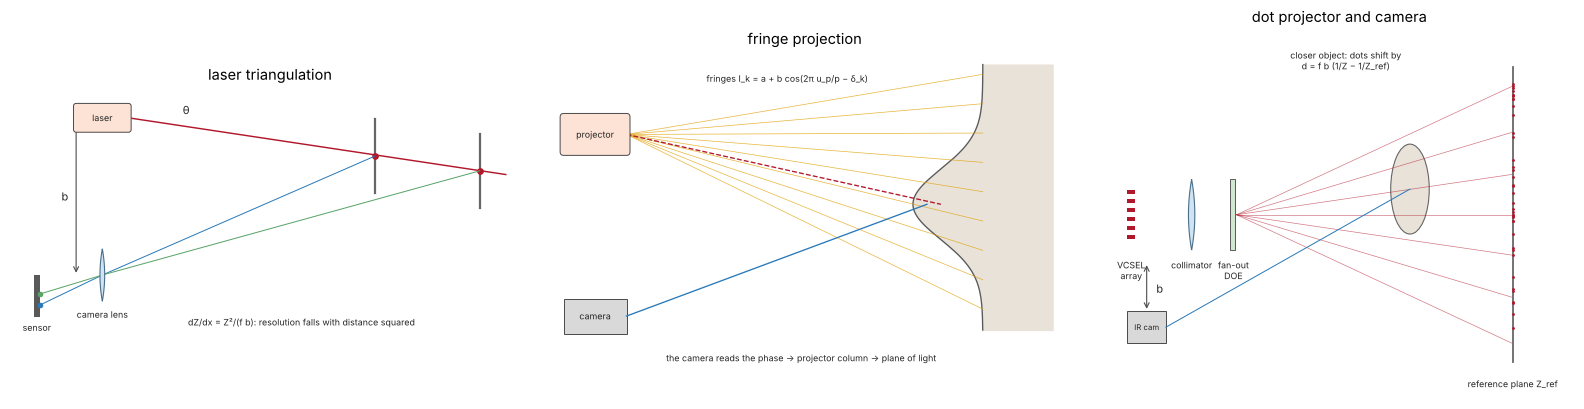

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
for ax, kind, title in zip(axs, ("triangulation", "fringe", "dots"),
                           ("laser triangulation", "fringe projection", "dot projector and camera")):
    sketch.structured_light_layout(ax, kind, title=title)
plt.show()

## 1. Laser triangulation

A camera with a lens of focal length $f$ looks along $Z$; a laser at the
baseline $b$ sends its beam at the angle $\theta$ towards the camera axis.
A spot at the depth $Z$ images to $x = f\,(b/Z - \tan\theta)$, so

$$
Z = \frac{f b}{x + f\tan\theta}, \qquad \left|\frac{dZ}{dx}\right| = \frac{Z^2}{f b}.
$$

A shift of the spot by one pixel means a depth change that grows with
the square of the distance: twice as far, four times worse. Longer
baselines and focal lengths help, at the price of a smaller field and of
shadows (points that the laser lights but the camera does not see).
A sensor head with $b = 100$ mm, $f = 25$ mm and 5 µm pixels:

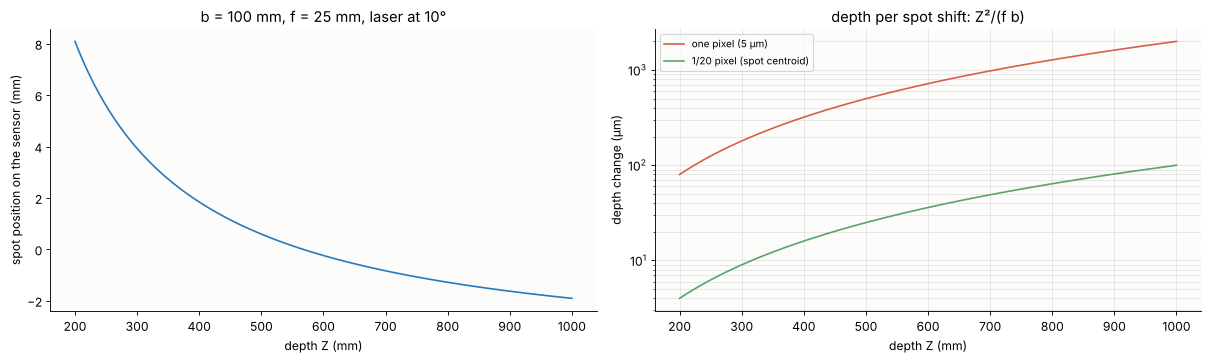

Z = 200 mm: 80 um per pixel, 4.0 um per 1/20 pixel
Z = 1000 mm: 2000 um per pixel, 100.0 um per 1/20 pixel


In [3]:
F_MM, B_MM, PIX = 25.0, 100.0, 5e-3
TH = np.radians(10.0)
Z = np.linspace(200, 1000, 200)
x_img = F_MM*(B_MM/Z - np.tan(TH))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
axs[0].plot(Z, x_img, color=BLUE)
axs[0].set_xlabel("depth Z (mm)")
axs[0].set_ylabel("spot position on the sensor (mm)")
axs[0].set_title("b = 100 mm, f = 25 mm, laser at 10°")
axs[1].semilogy(Z, sl.triangulation_sensitivity(Z, B_MM, F_MM)*PIX*1e3, color=RED,
                label="one pixel (5 µm)")
axs[1].semilogy(Z, sl.triangulation_sensitivity(Z, B_MM, F_MM)*PIX/20*1e3, color=GREEN,
                label="1/20 pixel (spot centroid)")
axs[1].set_xlabel("depth Z (mm)")
axs[1].set_ylabel("depth change (µm)")
axs[1].set_title("depth per spot shift: Z²/(f b)")
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3, which="both")
plt.show()
for z in (200.0, 1000.0):
    print("Z = {:.0f} mm: {:.0f} um per pixel, {:.1f} um per 1/20 pixel".format(
        z, sl.triangulation_sensitivity(z, B_MM, F_MM)*PIX*1e3,
        sl.triangulation_sensitivity(z, B_MM, F_MM)*PIX/20*1e3))

At 200 mm a pixel is 80 µm of depth, at 1 m already 2 mm. The centroid
of a spot spread over a few pixels can be found to a twentieth of a
pixel or better in an ideal image, which would give 4 µm at 200 mm. On a
rough surface it cannot: the laser spot is a **speckle** pattern, and
its centroid wanders with the random phases of the surface. Dorsch,
Häusler and Herrmann showed that the resulting uncertainty of the
centroid in the object does not depend on the pixels or the spot size,
only on the observation aperture $\sin u$:

$$
\delta x \approx \frac{C\lambda}{2\pi\sin u}, \qquad
\delta Z \approx \frac{C\lambda}{2\pi\sin u\,\sin\theta_\mathrm{tri}},
$$

with the speckle contrast $C$ and the triangulation angle
$\theta_\mathrm{tri}$ between illumination and observation. Below a 2D
simulation: a Gaussian laser spot on a surface with random phase,
imaged coherently through a circular pupil, and the scatter of the
centroid over 150 surfaces.

simulated / formula: 0.62, 0.71, 0.74, 0.72, 0.68


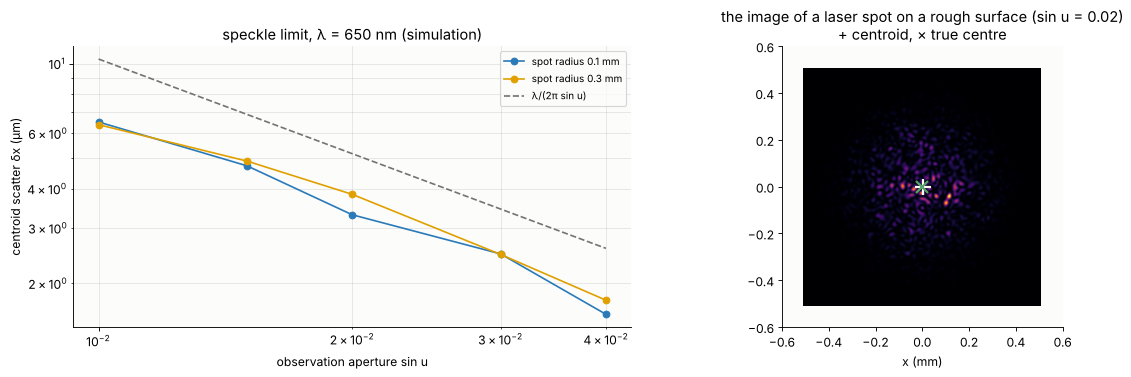

In [4]:
rng = np.random.default_rng(0)
LAM = 0.65e-3                       # mm
n, dx = 256, 4e-3
x = (np.arange(n) - n/2)*dx
X, Y = np.meshgrid(x, x)
fx = np.fft.fftfreq(n, dx)
FX, FY = np.meshgrid(fx, fx)
NAs = np.array([0.01, 0.015, 0.02, 0.03, 0.04])
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for w, c in ((0.1, BLUE), (0.3, ORANGE)):
    scatter = []
    for NA in NAs:
        pupil = FX**2 + FY**2 <= (NA/LAM)**2
        cx = []
        for k in range(150):
            field = np.exp(-(X**2 + Y**2)/w**2)*np.exp(2j*np.pi*rng.random((n, n)))
            I = np.abs(np.fft.ifft2(np.fft.fft2(field)*pupil))**2
            cx.append(np.sum(I*X)/np.sum(I))
        scatter.append(np.std(cx))
    axs[0].loglog(NAs, np.array(scatter)*1e3, "o-", color=c, label="spot radius {:.1f} mm".format(w))
axs[0].loglog(NAs, LAM/(2*np.pi*NAs)*1e3, color=GREY, ls="--", label="λ/(2π sin u)")
axs[0].set_xlabel("observation aperture sin u")
axs[0].set_ylabel("centroid scatter δx (µm)")
axs[0].set_title("speckle limit, λ = 650 nm (simulation)")
axs[0].legend(fontsize=9)
axs[0].grid(alpha=0.3, which="both")
print("simulated / formula: " + ", ".join("{:.2f}".format(s/(LAM/(2*np.pi*a)))
                                          for s, a in zip(scatter, NAs)))

field = np.exp(-(X**2 + Y**2)/0.3**2)*np.exp(2j*np.pi*rng.random((n, n)))
I = np.abs(np.fft.ifft2(np.fft.fft2(field)*(FX**2 + FY**2 <= (0.02/LAM)**2)))**2
axs[1].imshow(I, extent=[x[0], x[-1], x[0], x[-1]], cmap="inferno")
axs[1].plot(np.sum(I*X)/np.sum(I), np.sum(I*Y)/np.sum(I), "+", color="w", ms=14, mew=2)
axs[1].plot(0, 0, "x", color=GREEN, ms=10, mew=2)
axs[1].set_xlim(-0.6, 0.6)
axs[1].set_ylim(-0.6, 0.6)
axs[1].set_xlabel("x (mm)")
axs[1].set_title("the image of a laser spot on a rough surface (sin u = 0.02)\n"
                 "+ centroid, × true centre")
plt.show()

The centroid scatter does not depend on the spot size and falls as
$1/\sin u$, as Dorsch and colleagues found; our simulation gives about
0.7 times their estimate. For a triangulation sensor at 200 mm with a
25 mm lens at f/4 ($\sin u \approx 0.016$) and $\theta_\mathrm{tri} =
27°$, the speckle limit is about 10 µm of depth (15 µm by the formula), worse than the 4 µm the
pixels would allow. Larger apertures, white light or incoherent LEDs,
and averaging along a line of independent speckles beat the limit; a
smaller pixel never does.

## 2. Fringe projection

A projector replaces the laser spot with a whole field of sinusoidal
fringes along its columns, $I_k = a + b\cos(2\pi u_p/p - \delta_k)$,
shown with $N$ phase steps $\delta_k = 2\pi k/N$. For every camera pixel,
the N-step algorithm (`interferometry.psi_n_step()`) returns the phase
$2\pi u_p/p$ modulo $2\pi$: it tells which projector column lit the
point, up to a multiple of the period. **Temporal phase unwrapping**
removes the ambiguity: a coarse pattern whose period covers the whole
projector gives an unambiguous but noisy column, which unwraps the next
finer pattern, and so on. Every camera pixel then knows its projector
column $u_p$, and the 3D point is where the camera ray meets the plane of
light of that column (`triangulate_column()`): the projector is a camera
run backwards.

The scene: a reference plane at 800 mm, a smooth bump and a block with
a 40 mm step, seen by a 400 × 300 camera, lit by an 800 × 600 projector
at a baseline of 200 mm.

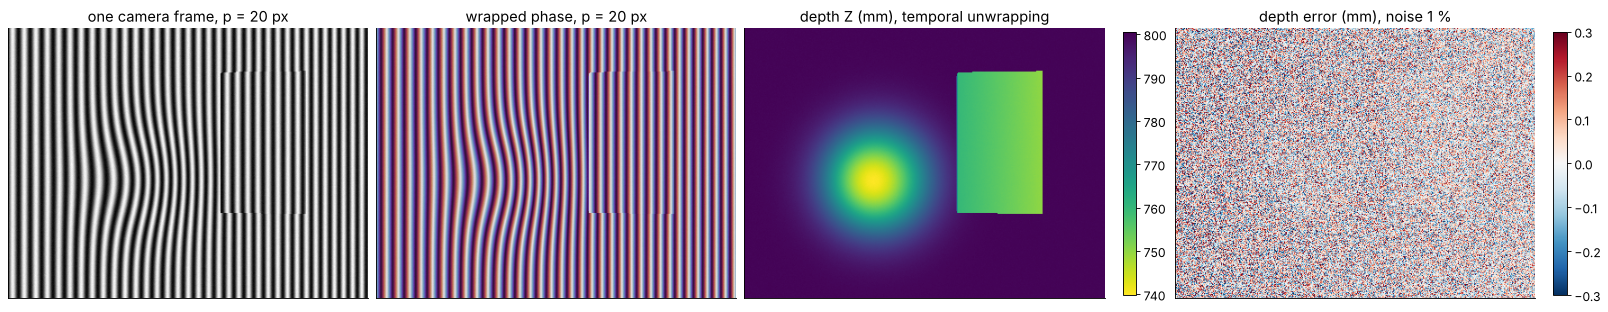

rms depth error 0.146 mm on the plane, 0.145 mm overall; gross errors (> 2 mm): 0


In [5]:
Z0 = 800.0


def scene(Xw, Yw):
    """Depth of the scene: plane at Z0, a Gaussian bump and a block with a step."""
    z = Z0 - 60*np.exp(-((Xw + 60)**2 + (Yw - 20)**2)/(2*45.0**2))
    block = (Xw > 40) & (Xw < 140) & (Yw > -110) & (Yw < 60)
    return np.where(block, Z0 - 40.0 - 0.1*(Xw - 40), z)


cam = sl.Pinhole([0, 0, 0], sl.look_at([0, 0, 0], [0, 0, Z0]), 700, (400, 300))
proj = sl.Pinhole([200, 0, 0], sl.look_at([200, 0, 0], [0, 0, Z0]), 1300, (800, 600))
uc, vc = cam.pixel_grid()
P_true = sl.intersect_depth(cam.position, cam.rays(uc, vc), scene, z_range=(600, 900))
up_true, vp_true = proj.project(P_true)
lit = (up_true >= 0) & (up_true < proj.size[0]) & (vp_true >= 0) & (vp_true < proj.size[1])

PERIODS = [820.0, 128.0, 20.0]
NOISE = 0.01


def capture(period, n_steps=4, gamma=1.0, noise=NOISE, seed=0):
    """Camera frames of N phase-shifted fringes, with Gaussian noise."""
    frames = 0.1 + 0.8*sl.fringe_patterns(up_true, period, n_steps, gamma=gamma)
    return frames + noise*np.random.default_rng(seed).standard_normal(frames.shape)


phases = [psi_n_step(capture(p, seed=k))[0] for k, p in enumerate(PERIODS)]
u_dec = sl.temporal_unwrap(phases, PERIODS)
P_dec = sl.triangulate_column(cam, proj, uc, vc, u_dec)
err = np.where(lit, P_dec[..., 2] - P_true[..., 2], np.nan)

fig, axs = plt.subplots(1, 4, figsize=(20, 4.2), layout="constrained")
axs[0].imshow(capture(20.0)[..., 0], cmap="gray")
axs[0].set_title("one camera frame, p = 20 px")
axs[1].imshow(np.where(lit, phases[2], np.nan), cmap="twilight")
axs[1].set_title("wrapped phase, p = 20 px")
im = axs[2].imshow(np.where(lit, P_dec[..., 2], np.nan), cmap="viridis_r")
axs[2].set_title("depth Z (mm), temporal unwrapping")
plt.colorbar(im, ax=axs[2], shrink=0.8)
im = axs[3].imshow(err, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
axs[3].set_title("depth error (mm), noise 1 %")
plt.colorbar(im, ax=axs[3], shrink=0.8)
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()
flat = lit & (np.abs(P_true[..., 0]) < 400) & (P_true[..., 2] > Z0 - 0.5)
print("rms depth error {:.3f} mm on the plane, {:.3f} mm overall; gross errors (> 2 mm): {}".format(
    np.nanstd(err[flat]), np.nanstd(err), np.sum(np.abs(err) > 2)))

Three periods with four steps each (12 frames) reconstruct the scene
with a depth noise of about 0.15 mm rms, including the step of the block,
which no spatial unwrapping could bridge reliably: the step shifts the
fringes by more than a period. Below, the wrapped phase of the finest
pattern unwrapped spatially (quality guided, from notebook 22, phase unwrapping), which
loses the absolute order and the step:

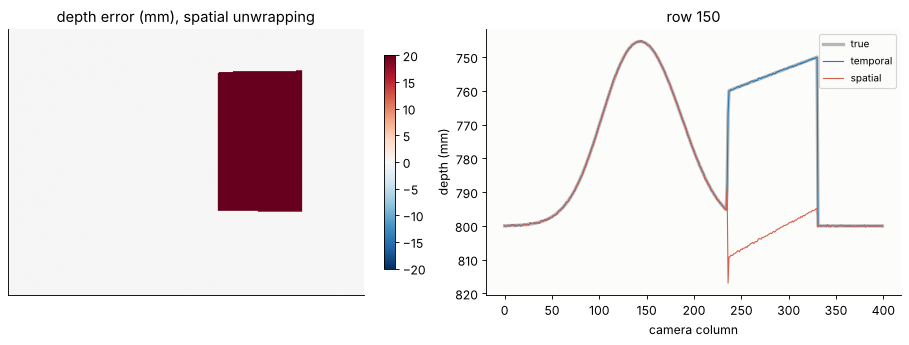

pixels off by more than 2 mm: spatial 12.5%, temporal 0.0%


In [6]:
psi = np.where(lit, phases[2], 0.0)
phi_sp = unwrap(psi, method="quality", mask=lit)
u_sp = PERIODS[2]*phi_sp/(2*np.pi)
# fix the global order with the true column at one pixel (spatial unwrapping cannot know it)
i0 = (150, 100)
u_sp += PERIODS[2]*np.round((up_true[i0] - u_sp[i0])/PERIODS[2])
P_sp = sl.triangulate_column(cam, proj, uc, vc, u_sp)
err_sp = np.where(lit, P_sp[..., 2] - P_true[..., 2], np.nan)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
im = axs[0].imshow(err_sp, cmap="RdBu_r", vmin=-20, vmax=20)
axs[0].set_title("depth error (mm), spatial unwrapping")
plt.colorbar(im, ax=axs[0], shrink=0.8)
axs[1].plot(P_true[150, :, 2], color=GREY, lw=3, alpha=0.5, label="true")
axs[1].plot(P_dec[150, :, 2], color=BLUE, lw=1, label="temporal")
axs[1].plot(P_sp[150, :, 2], color=RED, lw=1, label="spatial")
axs[1].invert_yaxis()
axs[1].set_xlabel("camera column")
axs[1].set_ylabel("depth (mm)")
axs[1].set_title("row 150")
axs[1].legend(fontsize=9)
for ax in axs[:1]:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()
print("pixels off by more than 2 mm: spatial {:.1%}, temporal {:.1%}".format(
    np.mean(np.abs(err_sp[lit]) > 2), np.mean(np.abs(err[lit]) > 2)))

The spatial unwrapper follows the phase continuously across the step
and puts the block at the wrong depth: the step is an integer number of
fringes plus a fraction that the wrapped phase cannot distinguish from
a smaller step. Temporal unwrapping measures every pixel independently.

**Noise and the fringe period.** With the intensity noise $\sigma_I$, the
N-step phase has the noise $\sigma_\varphi = \sqrt{2/N}\,\sigma_I/b$
(with $b$ the fringe amplitude), and the projector column
$\sigma_u = p\,\sigma_\varphi/(2\pi)$: finer fringes give proportionally
less depth noise, until the camera or the projector optics no longer
resolve them. The coarser patterns only need to be good enough to pick
the right fringe order of the next one; the ratio of successive periods
is limited by their noise.

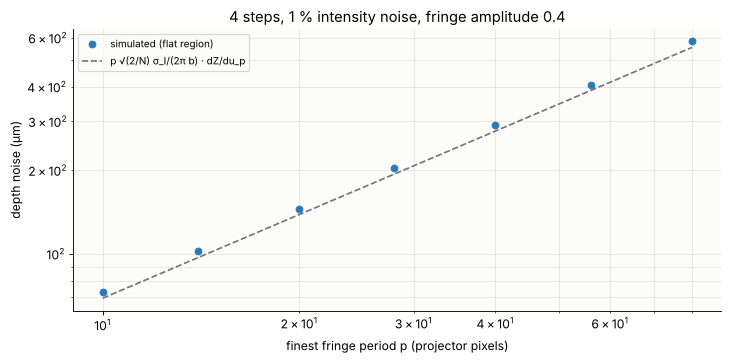

dZ/du_p on the plane: 2.46 mm per projector pixel


In [7]:
periods = np.array([10, 14, 20, 28, 40, 56, 80])
sig_z = []
for p in periods:
    ph = [psi_n_step(capture(pp, seed=10 + k))[0] for k, pp in enumerate([820.0, 128.0, p])]
    u = sl.temporal_unwrap(ph, [820.0, 128.0, p])
    Pz = sl.triangulate_column(cam, proj, uc, vc, u)[..., 2]
    sig_z.append(np.nanstd((Pz - P_true[..., 2])[flat]))
sig_u = periods*np.sqrt(2/4)*NOISE/0.4/(2*np.pi)
dz_du = Z0**2/(proj.focal*200.0)          # Z^2/(f b): depth per projector column
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
ax.loglog(periods, np.array(sig_z)*1e3, "o", color=BLUE, label="simulated (flat region)")
ax.loglog(periods, sig_u*dz_du*1e3, color=GREY, ls="--",
          label="p √(2/N) σ_I/(2π b) · dZ/du_p")
ax.set_xlabel("finest fringe period p (projector pixels)")
ax.set_ylabel("depth noise (µm)")
ax.set_title("4 steps, 1 % intensity noise, fringe amplitude 0.4")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.show()
print("dZ/du_p on the plane: {:.2f} mm per projector pixel".format(dz_du))

The depth noise follows the prediction, proportional to the period:
0.07 mm at 10 pixels, 0.6 mm at 80 pixels, with a sensitivity of
2.5 mm of depth per projector column at 800 mm. Commercial scanners
add more steps, average frames, and use the finest period the optics
transfer with good contrast.

**The gamma of the projector.** A projector shows $I^\gamma$ for a
commanded $I$ ($\gamma \approx 2.2$ for displays), which distorts the
sinusoid and adds harmonics. An N-step algorithm is blind to the
harmonics up to order $N - 2$ and aliases the others into a phase error
that repeats $N$ times per fringe. Three steps suffer from the second
harmonic, four from the third; eight steps are nearly immune:

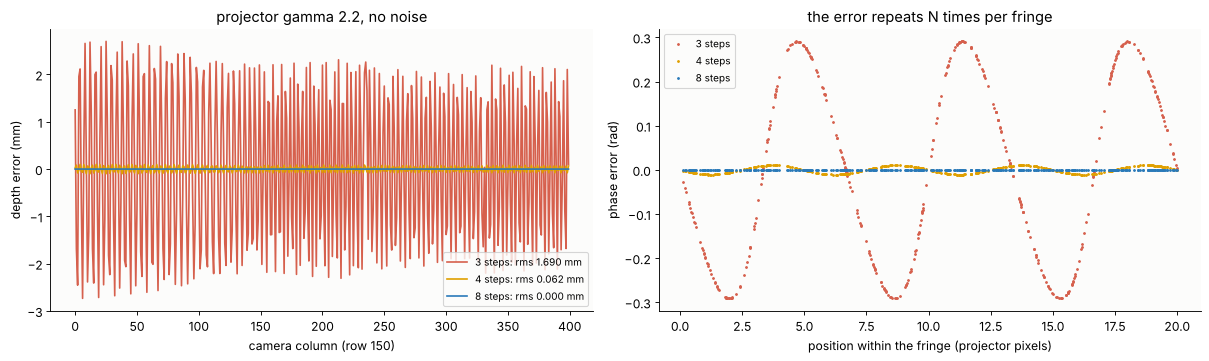

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
row = 150
for n_steps, c in ((3, RED), (4, ORANGE), (8, BLUE)):
    frames = [0.1 + 0.8*sl.fringe_patterns(up_true, p, n_steps, gamma=2.2) for p in PERIODS]
    shifts = 2*np.pi*np.arange(n_steps)/n_steps
    ph = [psi_n_step(f)[0] for f in frames]
    u = sl.temporal_unwrap(ph, PERIODS)
    Pz = sl.triangulate_column(cam, proj, uc, vc, u)[..., 2]
    e = np.where(lit, Pz - P_true[..., 2], np.nan)
    axs[0].plot(e[row], color=c, label="{} steps: rms {:.3f} mm".format(n_steps, np.nanstd(e[flat])))
    phase_err = np.angle(np.exp(1j*(ph[2] - 2*np.pi*up_true/PERIODS[2])))
    axs[1].plot((up_true[row, :] % PERIODS[2]), phase_err[row], ".", ms=3, color=c,
                label="{} steps".format(n_steps))
axs[0].set_xlabel("camera column (row 150)")
axs[0].set_ylabel("depth error (mm)")
axs[0].set_title("projector gamma 2.2, no noise")
axs[0].legend(fontsize=9)
axs[1].set_xlabel("position within the fringe (projector pixels)")
axs[1].set_ylabel("phase error (rad)")
axs[1].set_title("the error repeats N times per fringe")
axs[1].legend(fontsize=9)
plt.show()

With a gamma of 2.2, three steps leave a phase error of ±0.3 rad, a depth
ripple of ±2.5 mm (ridges three times per fringe, ten times the noise of
the previous section), four steps ±0.01 rad and 0.06 mm rms, and eight
steps none that matters. Gamma is also why fringe projectors either calibrate their
intensity response, or defocus binary patterns (which a blur turns into
sinusoids) so that the nonlinearity no longer matters.

## 3. The dot projector

Depth cameras of phones and game consoles project a pattern of
infrared dots and read the depth from how the pattern shifts. The
projector: a VCSEL array with a few hundred emitters at random positions
sits in the focal plane of a collimator lens, so each emitter becomes a
beam in its own direction; a diffractive **fan-out grating** then copies
this cluster of beams into a grid of diffraction orders, tiling the
field with copies of the pattern. A camera at the baseline $b$ sees the
dots; against an image of a reference plane at $Z_\mathrm{ref}$, every
dot near the camera is shifted by the disparity

$$
d = f b\left(\frac{1}{Z} - \frac{1}{Z_\mathrm{ref}}\right)
$$

(in pixels for $f$ in pixels), which block matching finds window by
window. The copies must not be confused: the tiles must be farther apart
in the image than the largest disparity.

First the fan-out grating: a 5 × 5 array of equal orders from one
period of 32 × 32 pixels, designed with the IFTA of `fanout_ifta()`,
continuous, with four phase levels and binary.

continuous: efficiency 93.3%, nonuniformity (max-min)/(max+min) 0.0%, zero order 3.73%


4 levels  : efficiency 70.1%, nonuniformity (max-min)/(max+min) 2.1%, zero order 2.80%


binary    : efficiency 63.2%, nonuniformity (max-min)/(max+min) 1.8%, zero order 2.50%


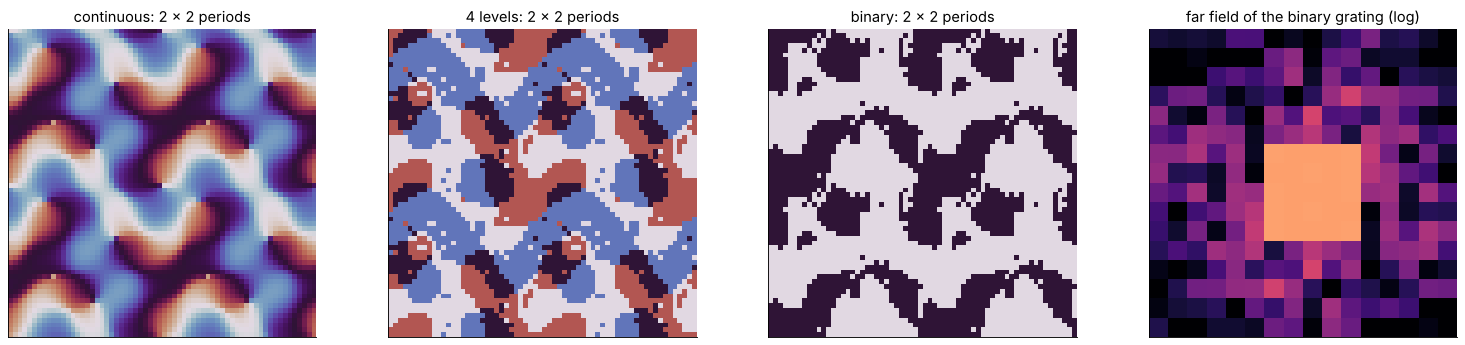

In [9]:
ORDERS = np.array([(i, j) for i in range(-2, 3) for j in range(-2, 3)])
fig, axs = plt.subplots(1, 4, figsize=(19, 4.2), layout="constrained")
designs = {}
for k, (levels, name) in enumerate(((None, "continuous"), (4, "4 levels"), (2, "binary"))):
    # quantized designs depend on the random start: keep the best of 8
    runs = [sl.fanout_ifta(32, ORDERS, 300, levels=levels, rng=seed) for seed in range(8)]
    phase, eta = max(runs, key=lambda r: r[1].sum()*(1 - np.ptp(r[1])/(r[1].max() + r[1].min())))
    designs[name] = (phase, eta)
    if k < 2:
        im = axs[k].imshow(np.tile(phase, (2, 2)), cmap="twilight", vmin=0, vmax=2*np.pi)
        axs[k].set_title("{}: 2 × 2 periods".format(name))
        axs[k].set_xticks([])
        axs[k].set_yticks([])
    print("{:10s}: efficiency {:.1%}, nonuniformity (max-min)/(max+min) {:.1%}, "
          "zero order {:.2%}".format(name, eta.sum(), (eta.max() - eta.min())/(eta.max() + eta.min()),
                                     eta[len(eta)//2]))
im = axs[2].imshow(np.tile(designs["binary"][0], (2, 2)), cmap="twilight", vmin=0, vmax=2*np.pi)
axs[2].set_title("binary: 2 × 2 periods")
axs[2].set_xticks([])
axs[2].set_yticks([])
far = np.abs(np.fft.fftshift(np.fft.fft2(np.exp(1j*designs["binary"][0]))))**2/32**4
axs[3].imshow(np.log10(far[8:-8, 8:-8] + 1e-5), cmap="magma", vmin=-4, vmax=-1)
axs[3].set_title("far field of the binary grating (log)")
axs[3].set_xticks([])
axs[3].set_yticks([])
plt.show()

The continuous phase sends about 90 % of the light into the 25 orders,
equal to a fraction of a per cent. Four levels reach about 70 %, and the
binary grating, which is the cheapest to make, about 60 %, the rest
going to orders outside the grid. (A binary grating is symmetric: it
puts equal power into the orders $\pm m$, which suits a symmetric
grid.)

The zero order is the eye safety issue of a dot projector: if the
grating's etch depth is off, the undiffracted beam grows, and it carries
the light of all emitters straight ahead. If the grating cracks or falls
off, the full VCSEL power leaves as the collimated cluster; projectors
monitor the integrity of the grating and switch off when it fails.

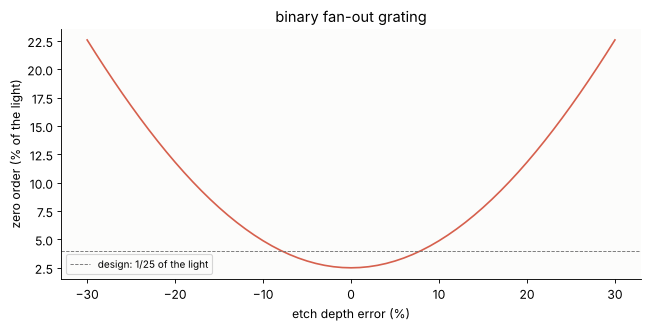

zero order at +10 % depth error: 4.9% (design 2.5%)


In [10]:
depth_err = np.linspace(-0.3, 0.3, 61)
phase_b = designs["binary"][0]
z0 = [sl.order_efficiencies(phase_b*(1 + e), np.array([[0, 0]]))[0] for e in depth_err]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(depth_err*100, np.array(z0)*100, color=RED)
ax.axhline(100/25, color=GREY, ls="--", lw=0.8, label="design: 1/25 of the light")
ax.set_xlabel("etch depth error (%)")
ax.set_ylabel("zero order (% of the light)")
ax.set_title("binary fan-out grating")
ax.legend(fontsize=9)
plt.show()
print("zero order at +10 % depth error: {:.1%} (design {:.1%})".format(
    np.interp(0.1, depth_err, z0), z0[30]))

A 10 % deeper etch roughly doubles the zero order: the eye safety
analysis of notebook 130 (time-of-flight LiDAR) applies to the brightest
dot, and fabrication tolerances enter it directly.

Now the camera: 640 × 480 pixels with $f = 900$ px (a field of ±20°
horizontally), the projector 50 mm to its side. 300 emitters within
±0.12 mm in the focal plane of a 2 mm collimator make a tile of ±3.4°;
the grating with a period of 7.8 µm at 940 nm spaces the orders by the
tile width. The scene: a wall at 1000 mm, a sphere and a tilted box.

7500 dots, DOE period 7.8 um, tile 6.9 deg


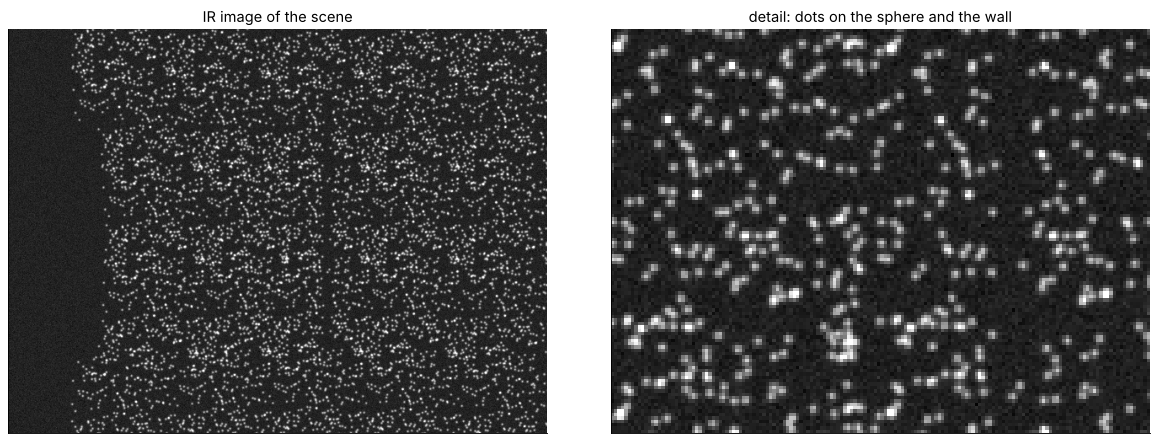

In [11]:
rng = np.random.default_rng(5)
WL = 940e-6                                  # mm
emitters = rng.uniform(-0.12, 0.12, (300, 2))
F_COL = 2.0
TILE = 2*0.12/np.sqrt(0.12**2 + F_COL**2)    # width of one tile in direction cosines
PERIOD_DOE = WL/TILE
phase_b, eta_b = designs["binary"]
k_dots = sl.dot_directions(emitters, F_COL, ORDERS, PERIOD_DOE, WL)
weights = np.repeat(eta_b, len(emitters))    # order efficiencies of the binary grating
print("{} dots, DOE period {:.1f} um, tile {:.1f} deg".format(len(k_dots), PERIOD_DOE*1e3,
                                                             np.degrees(np.arcsin(TILE))))

Z_REF, BASE = 1000.0, 50.0
cam2 = sl.Pinhole([0, 0, 0], np.eye(3), 900, (640, 480))
src = [BASE, 0.0, 0.0]


def scene2(Xw, Yw):
    """Wall at 1000 mm, a sphere of radius 120 mm at 700 mm, a tilted box."""
    z = np.full(np.broadcast(Xw, Yw).shape, 1000.0)
    r2 = (Xw + 110)**2 + (Yw - 10)**2
    sphere = np.where(r2 < 120**2, 700 - np.sqrt(np.maximum(120**2 - r2, 0)), np.inf)
    box = np.where((Xw > 60) & (Xw < 230) & (Yw > -150) & (Yw < 120), 820 + 0.6*(Xw - 60), np.inf)
    return np.minimum(z, np.minimum(sphere, box))


ref_img, _ = sl.render_dots(cam2, src, k_dots, lambda X, Y: Z_REF + 0*X, sigma=0.9, weights=weights)
img, _ = sl.render_dots(cam2, src, k_dots, scene2, sigma=0.9, weights=weights, z_range=(500, 1001))
noise_rng = np.random.default_rng(6)
img_n = img + 0.02*img.max()*noise_rng.standard_normal(img.shape)
ref_n = ref_img + 0.02*ref_img.max()*noise_rng.standard_normal(ref_img.shape)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4), layout="constrained")
axs[0].imshow(img_n, cmap="gray", vmax=0.6*img.max())
axs[0].set_title("IR image of the scene")
axs[1].imshow(img_n[180:300, 260:420], cmap="gray", vmax=0.6*img.max())
axs[1].set_title("detail: dots on the sphere and the wall")
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

block matching: 2.4 s


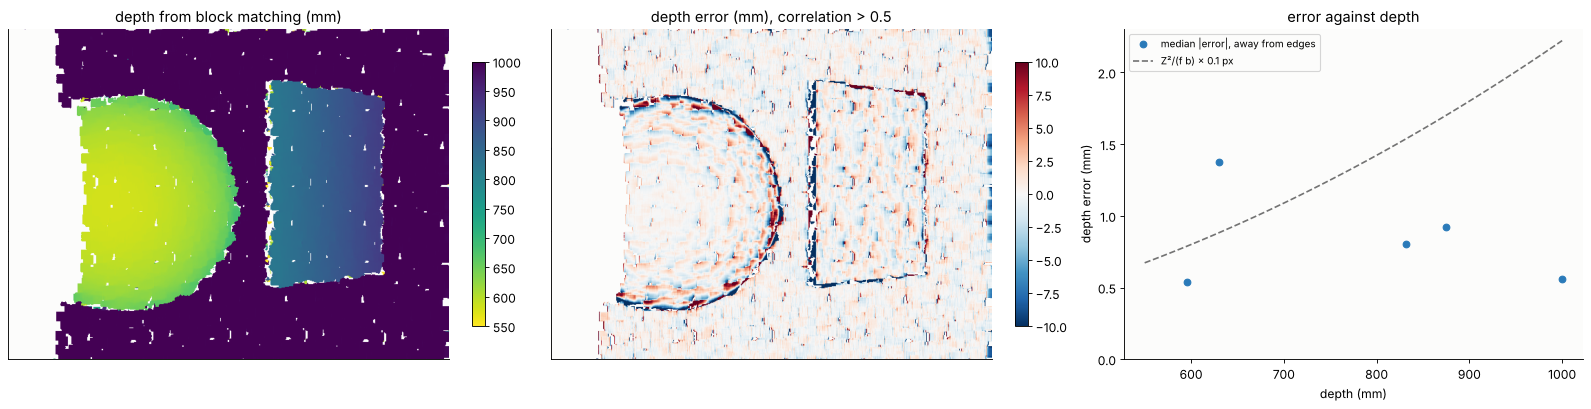

valid pixels: 83%; median |error| 0.67 mm; gross errors (> 20 mm) 1.6% of valid, 0.1% away from edges


In [12]:
t0 = time.time()
disp, score = sl.block_match(img_n, ref_n, window=13, max_disparity=40, min_disparity=-3)
Z_est = sl.depth_from_disparity(disp, BASE, cam2.focal, Z_REF)
uu, vv = cam2.pixel_grid()
P2 = sl.intersect_depth(cam2.position, cam2.rays(uu, vv), scene2, z_range=(500, 1001))
err2 = Z_est - P2[..., 2]
valid = score > 0.5
print("block matching: {:.1f} s".format(time.time() - t0))

fig, axs = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
im = axs[0].imshow(np.where(valid, Z_est, np.nan), cmap="viridis_r", vmin=550, vmax=1000)
axs[0].set_title("depth from block matching (mm)")
plt.colorbar(im, ax=axs[0], shrink=0.8)
im = axs[1].imshow(np.where(valid, err2, np.nan), cmap="RdBu_r", vmin=-10, vmax=10)
axs[1].set_title("depth error (mm), correlation > 0.5")
plt.colorbar(im, ax=axs[1], shrink=0.8)
for ax in axs[:2]:
    ax.set_xticks([])
    ax.set_yticks([])
inner = valid.copy()
inner[:, :60] = False                         # left edge: no reference to match
zt = P2[..., 2]
# away from depth edges (windows that straddle two surfaces)
from scipy.ndimage import maximum_filter
edges = maximum_filter(np.hypot(*np.gradient(zt)) > 3.0, size=15)
smooth = inner & ~edges
bins = np.array([560, 620, 680, 760, 840, 940, 1001])
rms, zc = [], []
for a, b in zip(bins[:-1], bins[1:]):
    sel = smooth & (zt >= a) & (zt < b)
    if sel.sum() > 200:
        rms.append(np.nanmedian(np.abs(err2[sel])))
        zc.append(np.nanmedian(zt[sel]))
zc = np.array(zc)
axs[2].plot(zc, rms, "o", color=BLUE, label="median |error|, away from edges")
axs[2].plot([], [], color=GREY, ls="--", label="Z²/(f b) × 0.1 px")
axs[2].set_xlabel("depth (mm)")
axs[2].set_ylabel("depth error (mm)")
axs[2].set_title("error against depth")
zz = np.linspace(550, 1000, 50)
axs[2].plot(zz, zz**2/(cam2.focal*BASE)*0.1, color=GREY, ls="--")
axs[2].set_ylim(0, None)
axs[2].legend(fontsize=9)
plt.show()
print("valid pixels: {:.0%}; median |error| {:.2f} mm; gross errors (> 20 mm) {:.1%} of valid, "
      "{:.1%} away from edges".format(valid.mean(), np.nanmedian(np.abs(err2[inner])),
                                       np.mean(np.abs(err2[inner]) > 20), np.mean(np.abs(err2[smooth]) > 20)))

Block matching with 13 × 13 pixel windows recovers the scene: the sphere,
the tilted box and the wall, with a typical error of 0.5 to 1.5 mm
between 600 mm and 1 m, a disparity error of a tenth of a pixel or less.
The error grows with the square of the depth, as for every
triangulation. Errors concentrate at the depth edges, where a window
straddles two surfaces (the "fattening" of foreground objects that all
block matching shows), and in the shadow of the projector beside the
sphere and the box, where no dots fall. The left edge of the image has
no counterpart in the reference image and is lost too.

The numbers of a real phone camera are similar: a baseline of a few
centimetres, about 30 000 dots, and depth errors of a millimetre at
arm's length growing to centimetres at a few metres, which is why such
sensors serve face recognition and room scanning, while cars use
LiDARs.

## Summary

- Triangulation trades timing for geometry: depth from an angle across a
  baseline, with a depth error per image shift of $Z^2/(fb)$.
- The speckle of a laser spot limits its centroid to about
  $\lambda/(2\pi\sin u)$ in the object, independent of pixels and spot
  size: larger apertures or incoherent light beat it.
- Fringe projection with phase shifting finds the projector column of
  every camera pixel; temporal unwrapping with a coarse-to-fine sequence
  of periods handles steps that spatial unwrapping cannot, the depth
  noise is proportional to the finest period, and the projector's gamma
  calls for more phase steps or calibration.
- A dot projector tiles a random VCSEL pattern with a fan-out grating
  designed by IFTA (60 to 90 % efficiency for 25 orders, from binary to
  continuous); block matching against a reference plane gives depth to
  about a tenth of a pixel of disparity. The zero order of the grating is
  part of the eye safety budget.

## References

- R. G. Dorsch, G. Häusler and J. M. Herrmann, "Laser triangulation:
  fundamental uncertainty in distance measurement", Appl. Opt. 33, 1306
  (1994).
- S. Zhang, "High-speed 3D shape measurement with structured light
  methods: a review", Opt. Lasers Eng. 106, 119 (2018).
- C. Zuo, L. Huang, M. Zhang, Q. Chen and A. Asundi, "Temporal phase
  unwrapping algorithms for fringe projection profilometry: a
  comparative review", Opt. Lasers Eng. 85, 84 (2016).
- J. Geng, "Structured-light 3D surface imaging: a tutorial", Adv. Opt.
  Photonics 3, 128 (2011).
- B. Freedman, A. Shpunt, M. Machline and Y. Arieli, "Depth mapping
  using projected patterns", US patent 8,150,142 (2012).
- F. Wyrowski, "Diffractive optical elements: iterative calculation of
  quantized, blazed phase structures", J. Opt. Soc. Am. A 7, 961 (1990).
- D. Scharstein and R. Szeliski, "A taxonomy and evaluation of dense
  two-frame stereo correspondence algorithms", Int. J. Comput. Vis. 47,
  7 (2002).

In [13]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 17 s
